# Práctica 2 · Alineamientos de secuencias con Biopython
**Asignatura:** Bioinformática · Grado en Ciencia e Ingeniería de Datos (ULPGC)
**Integrantes:** Lucía Xufang Cruz Toste y Carlota Ayala Pérez



## Ejercicio 1 · Búsqueda en rejilla de penalizaciones de huecos

Se comparan dos secuencias de ADN: una original (`GCATGCATGCATGC`) y otra más corta (`GCATGCGC`). El alineamiento es **global**. La puntuación premia las coincidencias (`+1`), deja las sustituciones en `0` y penaliza la apertura y la extensión de huecos.

Para un tramo de hueco de longitud $L$, la penalización afín que usa Biopython es $g_{apertura}+(L-1)\,g_{extensión}$. Se explora una rejilla de `open_gap` (−1 a −20, paso 1) y `extend_gap` (−0.1 a −5.0, paso 0.1) y se guarda en un DataFrame cuántos alineamientos alcanzan la puntuación óptima. Ese número puede ser mayor que uno cuando hay **empates**, sin que ello implique soluciones de distinta calidad.

In [1]:
import random
from io import StringIO
from pathlib import Path
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from Bio import Align, SeqIO
from Bio.Align import substitution_matrices

pd.set_option("display.max_columns", 20)

seq_sana = "GCATGCATGCATGC"
seq_paciente = "GCATGCGC"

# Rejilla elegida dentro del intervalo pedido por el enunciado.
aperturas = np.arange(-1, -21, -1)
extensiones = np.round(np.arange(-0.1, -5.01, -0.1), 2)

alineador = Align.PairwiseAligner()
alineador.mode = "global"
alineador.match_score = 1
alineador.mismatch_score = 0

resultados = []
for apertura in aperturas:
    for extension in extensiones:
        alineador.open_gap_score = float(apertura)
        alineador.extend_gap_score = float(extension)
        alineamientos = alineador.align(seq_sana, seq_paciente)
        resultados.append({
            "open_gap": float(apertura),
            "extend_gap": float(extension),
            "n_optimos": len(alineamientos),
            "mejor_score": alineamientos.score
        })

df_grid = pd.DataFrame(resultados)
print(f"Combinaciones analizadas: {len(df_grid)}")
display(df_grid.head(10))
print("Distribución del número de soluciones óptimas:")
display(df_grid["n_optimos"].value_counts().sort_index().rename_axis("n_optimos").to_frame("combinaciones"))

Combinaciones analizadas: 1000


,open_gap,extend_gap,n_optimos,mejor_score
0,-1.0,-0.1,1,6.5
1,-1.0,-0.2,1,6.0
2,-1.0,-0.3,1,5.5
3,-1.0,-0.4,1,5.0
4,-1.0,-0.5,1,4.5
5,-1.0,-0.6,1,4.0
6,-1.0,-0.7,1,3.5
7,-1.0,-0.8,1,3.0
8,-1.0,-0.9,1,2.5
9,-1.0,-1.0,9,2.0


Distribución del número de soluciones óptimas:


,combinaciones
n_optimos,
1,895
5,60
8,36
9,5
111,4


### Representación del espacio de parámetros

El mapa de calor muestra el **número de óptimos** (no la puntuación). Las filas van de `open_gap = -1` (arriba) a `-20` (abajo) y las columnas de `extend_gap = -0.1` (izquierda) a `-5.0` (derecha). Se ordenan explícitamente la tabla y las etiquetas para que los ejes coincidan con los datos.

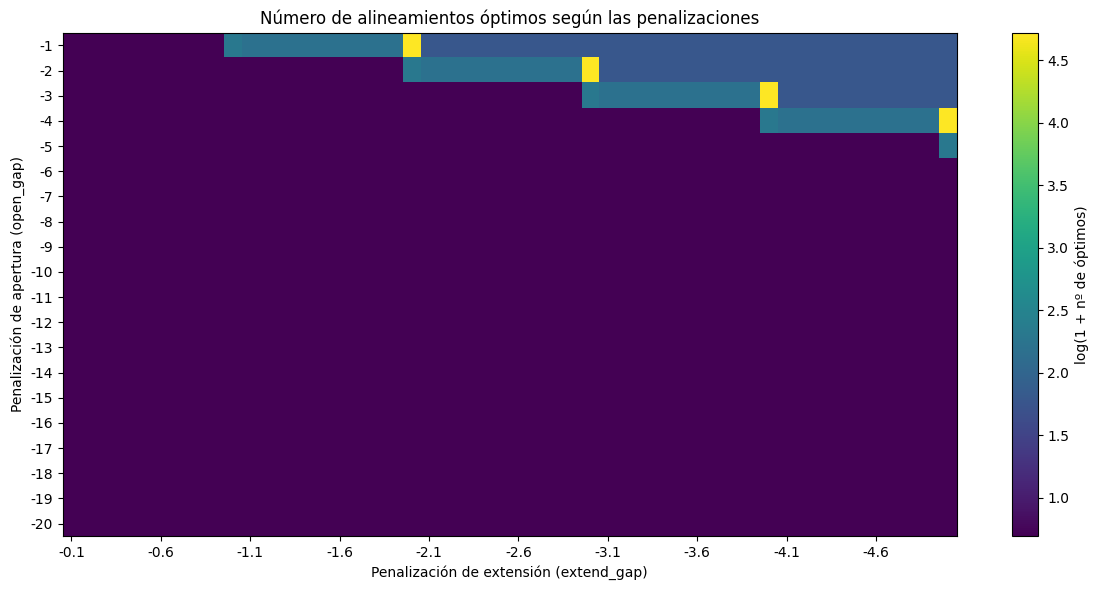

In [2]:
tabla_empates = df_grid.pivot(index="open_gap", columns="extend_gap", values="n_optimos")
# Orden explícito: -1 ... -20 en filas y -0.1 ... -5.0 en columnas.
tabla_empates = tabla_empates.sort_index(ascending=False).sort_index(axis=1, ascending=False)
valores_apertura = tabla_empates.index.to_numpy()
valores_extension = tabla_empates.columns.to_numpy()

fig, ax = plt.subplots(figsize=(12, 6))
im = ax.imshow(np.log1p(tabla_empates.values), aspect="auto", origin="upper", cmap="viridis")
pos_x = np.arange(0, len(valores_extension), 5)
ax.set_xticks(pos_x, labels=[f"{valores_extension[i]:.1f}" for i in pos_x])
ax.set_yticks(np.arange(len(valores_apertura)), labels=[f"{v:.0f}" for v in valores_apertura])
ax.set_xlabel("Penalización de extensión (extend_gap)")
ax.set_ylabel("Penalización de apertura (open_gap)")
ax.set_title("Número de alineamientos óptimos según las penalizaciones")
fig.colorbar(im, ax=ax, label="log(1 + nº de óptimos)")
plt.tight_layout()
plt.show()

### Localización matemática de la transición «múltiples empates → solución única»

Con este esquema compiten dos tipos de alineamiento global:

- **Un hueco de seis posiciones**, que conserva 8 coincidencias: $S_A = 8 + o + 5e$.
- **Dos huecos (4 y 2 posiciones)**, que conservan 8 coincidencias: $S_B = 8 + 2o + 4e$.

La igualdad $S_A = S_B$ se da cuando $8+o+5e = 8+2o+4e \Rightarrow \mathbf{o = e}$.
Como $S_A - S_B = e - o$:

- si $o < e$ (la apertura es **más** penalizada que la extensión) gana el hueco único ⇒ **una única solución óptima**;
- si $o = e$ hay empate entre ambas estrategias (y aparecen otras variantes) ⇒ **múltiples óptimos**;
- si $o > e$ (abrir es **más barato** que extender) se reparten los huecos de varias formas ⇒ **también múltiples óptimos**.

Primero se comprueba la frontera en un corte concreto (`extend_gap = -1`) y después se verifica sobre **toda la rejilla**.

In [3]:
def ejecutar_alineacion(apertura, extension):
    a = Align.PairwiseAligner()
    a.mode = "global"
    a.match_score = 1
    a.mismatch_score = 0
    a.open_gap_score = apertura
    a.extend_gap_score = extension
    return a.align(seq_sana, seq_paciente)

comparacion = []
for apertura in (-0.999, -1.0, -1.001):
    resultado = ejecutar_alineacion(apertura, -1.0)
    comparacion.append({"open_gap": apertura, "extend_gap": -1.0,
                        "n_optimos": len(resultado), "score": resultado.score})
display(pd.DataFrame(comparacion))

print("Solución única justo después de la frontera (open_gap = -1.001, extend_gap = -1):")
print(ejecutar_alineacion(-1.001, -1.0)[0])

o, e = -1.0, -1.0
print(f"En la frontera: S_A = {8 + o + 5*e:.1f}; S_B = {8 + 2*o + 4*e:.1f}")

,open_gap,extend_gap,n_optimos,score
0,-0.999,-1.0,8,2.002
1,-1.000,-1.0,9,2.000
2,-1.001,-1.0,1,1.999


Solución única justo después de la frontera (open_gap = -1.001, extend_gap = -1):
target            0 GCATGCATGCATGC 14
                  0 ||||||------|| 14
query             0 GCATGC------GC  8

En la frontera: S_A = 2.0; S_B = 2.0


In [4]:
# Verificación sobre toda la rejilla: ¿se cumple "única ⇔ open_gap < extend_gap"?
df_grid["regimen"] = np.where(
    np.isclose(df_grid["open_gap"], df_grid["extend_gap"]), "o = e",
    np.where(df_grid["open_gap"] < df_grid["extend_gap"], "o < e", "o > e"))

resumen_regimen = df_grid.groupby("regimen")["n_optimos"].agg(
    combinaciones="size",
    con_solucion_unica=lambda s: int((s == 1).sum()),
    min_optimos="min",
    max_optimos="max")
display(resumen_regimen)

unica = df_grid["n_optimos"] == 1
regla = df_grid["open_gap"] < df_grid["extend_gap"]
print("¿'solución única' coincide con 'open_gap < extend_gap' en las "
      f"{len(df_grid)} combinaciones? ->", bool((unica == regla).all()))

,combinaciones,con_solucion_unica,min_optimos,max_optimos
regimen,,,,
o < e,895,895,1,1
o = e,5,0,9,9
o > e,100,0,5,111


¿'solución única' coincide con 'open_gap < extend_gap' en las 1000 combinaciones? -> True


**Interpretación.** El punto de «colapso» no es un único valor, sino la **recta $o = e$** del espacio de parámetros: a un lado (apertura más penalizada que la extensión) el alineador concentra los huecos en un bloque largo y devuelve una única solución; en la recta y al otro lado aparecen empates. La celda anterior comprueba esta regla con las 1000 combinaciones de la rejilla.



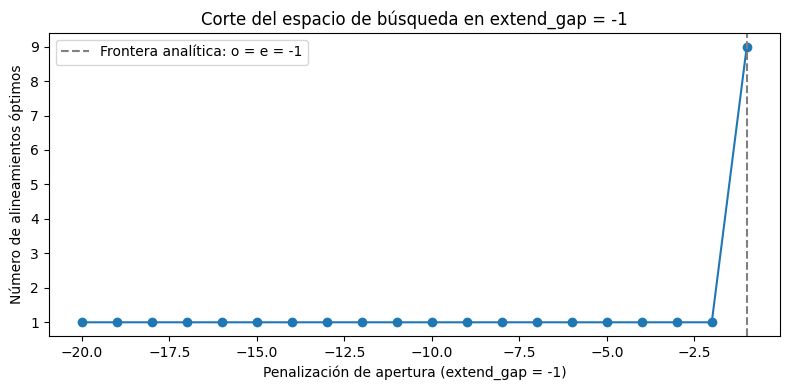

In [5]:
seccion = df_grid[df_grid["extend_gap"].eq(-1.0)]
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(seccion["open_gap"], seccion["n_optimos"], marker="o")
ax.axvline(-1, linestyle="--", color="gray", label="Frontera analítica: o = e = -1")
ax.set_xlabel("Penalización de apertura (extend_gap = -1)")
ax.set_ylabel("Número de alineamientos óptimos")
ax.set_title("Corte del espacio de búsqueda en extend_gap = -1")
ax.legend()
plt.tight_layout()
plt.show()

## Ejercicio 2 · Comparación «todos contra todos» de proteínas

Se lee con `Bio.SeqIO` un FASTA con cinco secuencias, se calculan los 25 valores de una matriz de puntuaciones mediante alineamiento **global** y la matriz **BLOSUM62**, y se representa como mapa de calor. Después se repite con otras matrices de sustitución.

**Limitación de los datos:** salvo que exista `proteinas_reales.fasta`, el FASTA es sintético. Los nombres de las variantes no representan especies reales ni permiten extraer conclusiones filogenéticas.

In [6]:
fasta_real = Path("proteinas_reales.fasta")

if fasta_real.exists():
    fasta_path = fasta_real
    usando_reales = True
else:
    usando_reales = False
    proteina_base = "MVLSPADKTNVKAAWGKVGAHAGEYGAEALERMFLSFPTTKTYFPHFDLSHGSAQVKGHGKKVADALTNAVAHVDDMPNALSALSDLHAHKLRVDPVNFKLLSHCLLVTLAAHLPAEFTPAVHASLDKFLASVSTVLTSKYR"
    variantes = {
        "Variante_1": {},
        "Variante_2": {8: "S"},
        "Variante_3": {8: "S", 18: "S", 65: "G"},
        "Variante_4": {8: "S", 18: "S", 65: "G", 90: "V", 110: "G", 120: "A"},
        "Variante_5": {8: "S", 18: "S", 65: "G", 90: "V", 110: "G", 120: "A", 25: "D", 45: "E", 80: "I"},
    }

    def mutar_secuencia(original, cambios):
        letras = list(original)
        for posicion, aminoacido in cambios.items():
            letras[posicion] = aminoacido
        return "".join(letras)

    fasta_path = Path("proteinas_practica2_sinteticas.fasta")
    with fasta_path.open("w", encoding="utf-8") as archivo:
        for nombre, cambios in variantes.items():
            archivo.write(f">{nombre} proteina_ejemplo_sintetica\n")
            archivo.write(mutar_secuencia(proteina_base, cambios) + "\n")

registros = list(SeqIO.parse(fasta_path, "fasta"))
nombres = [r.id for r in registros]
n = len(registros)
print("Origen de los datos:", "FASTA real aportado" if usando_reales else "FASTA sintético")
print("Secuencias cargadas:", n)
for r in registros:
    print(r.id, "| longitud:", len(r.seq))

Origen de los datos: FASTA sintético
Secuencias cargadas: 5
Variante_1 | longitud: 142
Variante_2 | longitud: 142
Variante_3 | longitud: 142
Variante_4 | longitud: 142
Variante_5 | longitud: 142


### Matriz de puntuaciones con BLOSUM62

Se calcula la puntuación de cada par (incluida cada secuencia consigo misma) con las mismas penalizaciones de huecos (`-10` apertura, `-0.5` extensión), como en los apuntes.

In [7]:
def matriz_puntuaciones(registros, nombre_matriz):
    a = Align.PairwiseAligner()
    a.mode = "global"
    a.substitution_matrix = substitution_matrices.load(nombre_matriz)
    a.open_gap_score = -10
    a.extend_gap_score = -0.5
    ids = [r.id for r in registros]
    valores = np.zeros((len(registros), len(registros)))
    for i, ri in enumerate(registros):
        for j, rj in enumerate(registros):
            valores[i, j] = a.score(ri.seq, rj.seq)
    return pd.DataFrame(valores, index=ids, columns=ids)

matriz_blosum62 = matriz_puntuaciones(registros, "BLOSUM62")
print(f"Matriz BLOSUM62 ({n} × {n} = {n*n} puntuaciones)")
display(matriz_blosum62)
assert matriz_blosum62.shape == (n, n)
assert np.allclose(matriz_blosum62.values, matriz_blosum62.values.T)

Matriz BLOSUM62 (5 × 5 = 25 puntuaciones)


,Variante_1,Variante_2,Variante_3,Variante_4,Variante_5
Variante_1,733.0,729.0,719.0,708.0,691.0
Variante_2,729.0,732.0,722.0,711.0,694.0
Variante_3,719.0,722.0,732.0,721.0,704.0
Variante_4,708.0,711.0,721.0,733.0,716.0
Variante_5,691.0,694.0,704.0,716.0,730.0


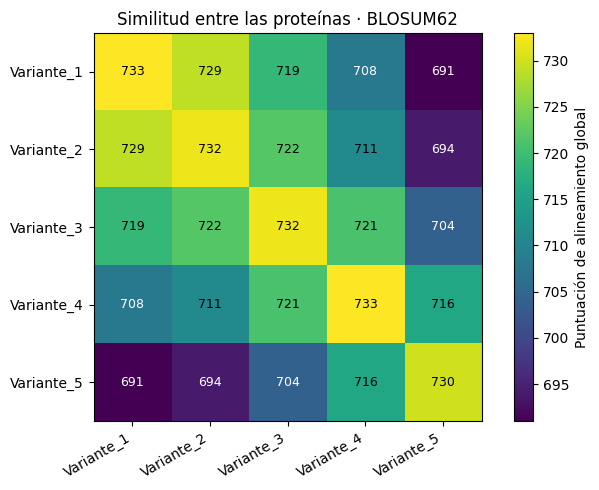

In [8]:
fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(matriz_blosum62.values, cmap="viridis")
ax.set_xticks(range(n), nombres, rotation=30, ha="right")
ax.set_yticks(range(n), nombres)
for i in range(n):
    for j in range(n):
        ax.text(j, i, f"{matriz_blosum62.iloc[i, j]:.0f}", ha="center", va="center",
                color="white" if im.norm(matriz_blosum62.iloc[i, j]) < 0.45 else "black", fontsize=9)
fig.colorbar(im, ax=ax, label="Puntuación de alineamiento global")
ax.set_title("Similitud entre las proteínas · BLOSUM62")
plt.tight_layout()
plt.show()

### Comparación con otras matrices de sustitución

Se repite el cálculo con **BLOSUM45** y **PAM250**. Cada matriz tiene su propia escala, por lo que **no se comparan los valores absolutos**. Para hacerlos comparables se **normaliza** cada puntuación por la autopuntuación más baja del par:

$$S_{norm}(i,j)=\frac{S(i,j)}{\min\big(S(i,i),\,S(j,j)\big)}$$

Así la diagonal vale 1 y el resto queda en una escala relativa entre matrices.

,Matriz,Media (bruta),Mín (bruta),Máx (bruta),Media (normalizada),Mín (normalizada),Máx (normalizada)
0,BLOSUM62,711.5,691.0,729.0,0.973,0.947,0.996
1,BLOSUM45,847.3,824.0,869.0,0.974,0.949,0.998
2,PAM250,646.8,633.0,659.0,0.981,0.962,0.998


Orden de similitud (de más a menos parecida a Variante_1):
  BLOSUM62  ['Variante_2', 'Variante_3', 'Variante_4', 'Variante_5']
  BLOSUM45  ['Variante_2', 'Variante_3', 'Variante_4', 'Variante_5']
  PAM250    ['Variante_2', 'Variante_3', 'Variante_4', 'Variante_5']


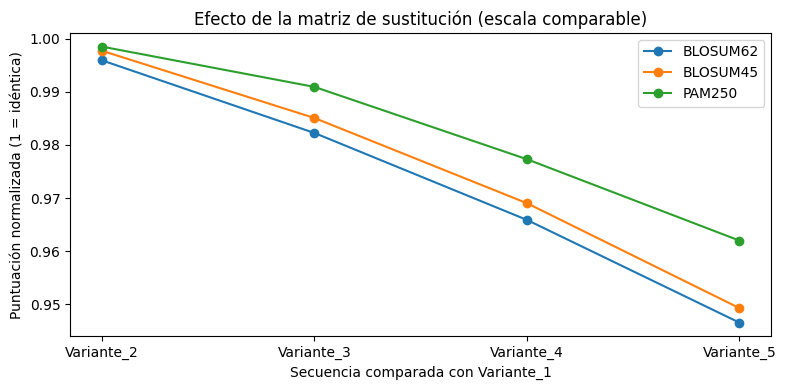

In [9]:
def normalizar(df):
    diag = np.diag(df.values)
    return pd.DataFrame(df.values / np.minimum.outer(diag, diag), index=df.index, columns=df.columns)

matrices = {"BLOSUM62": matriz_blosum62,
            "BLOSUM45": matriz_puntuaciones(registros, "BLOSUM45"),
            "PAM250": matriz_puntuaciones(registros, "PAM250")}
normalizadas = {k: normalizar(v) for k, v in matrices.items()}

indices_sup = np.triu_indices(n, k=1)
resumen = []
for nombre, df in matrices.items():
    bruto = df.values[indices_sup]
    norm = normalizadas[nombre].values[indices_sup]
    resumen.append({"Matriz": nombre,
                    "Media (bruta)": bruto.mean(), "Mín (bruta)": bruto.min(), "Máx (bruta)": bruto.max(),
                    "Media (normalizada)": norm.mean(), "Mín (normalizada)": norm.min(), "Máx (normalizada)": norm.max()})
display(pd.DataFrame(resumen).round(3))

# ¿Cambia el orden de similitud respecto a la primera secuencia según la matriz?
referencia = nombres[0]
print(f"Orden de similitud (de más a menos parecida a {referencia}):")
for nombre, df in matrices.items():
    orden = df.loc[referencia].drop(referencia).sort_values(ascending=False).index.tolist()
    print(f"  {nombre:9s}", orden)

fig, ax = plt.subplots(figsize=(8, 4))
for nombre, df in normalizadas.items():
    ax.plot(range(1, n), [df.iloc[0, j] for j in range(1, n)], marker="o", label=nombre)
ax.set_xticks(range(1, n), nombres[1:])
ax.set_xlabel(f"Secuencia comparada con {referencia}")
ax.set_ylabel("Puntuación normalizada (1 = idéntica)")
ax.set_title("Efecto de la matriz de sustitución (escala comparable)")
ax.legend()
plt.tight_layout()
plt.show()

**Interpretación.** La diagonal compara cada secuencia consigo misma y da las puntuaciones más altas. El mapa de calor es simétrico porque el esquema puntúa igual un par con independencia del orden. Con las variantes sintéticas, cuantas más mutaciones acumula una variante respecto a la primera, menor es su puntuación; la normalización muestra que BLOSUM62, BLOSUM45 y PAM250 mantienen la misma ordenación de similitud aunque con escalas distintas (la celda anterior imprime el orden con cada matriz). Para conclusiones evolutivas (p. ej. Humano–Chimpancé más parecidos que Humano–Mosca) hay que sustituir este FASTA por **secuencias reales de la misma proteína** (colocando `proteinas_reales.fasta`), citando su procedencia.

**Aportaciones adicionales.** Comprobación automática de simetría y de tamaño de la matriz; normalización para comparar matrices; comparación del orden de similitud entre matrices; lectura automática de un FASTA real si está disponible.

## Ejercicio 3 · Escalabilidad de los alineamientos

Se generan pares de secuencias de ADN de **100, 500, 1000, 2000 y 5000** bases con `random` y semilla fija. El tiempo se mide con `time.perf_counter` (alta resolución, en ms) y se reporta la **mediana** de varias repeticiones. Se miden dos operaciones:

- `.score()`: coste de obtener solo la puntuación óptima.
- `.align()` (recuperando el primer alineamiento): coste de **alinear** el par, que incluye el rastreo inverso. No se enumeran todos los óptimos (`len()` sobre el resultado) porque su número puede ser enorme.

In [10]:
random.seed(42)
longitudes = [100, 500, 1000, 2000, 5000]

def adn_aleatorio(longitud):
    return "".join(random.choices("ACGT", k=longitud))

alineador_tiempo = Align.PairwiseAligner()
alineador_tiempo.mode = "global"
alineador_tiempo.match_score = 1
alineador_tiempo.mismatch_score = -1
alineador_tiempo.open_gap_score = -2
alineador_tiempo.extend_gap_score = -0.5

tiempos = []
for longitud in longitudes:
    a, b = adn_aleatorio(longitud), adn_aleatorio(longitud)

    t_score = []
    for _ in range(3):
        inicio = perf_counter()
        puntuacion = alineador_tiempo.score(a, b)
        t_score.append((perf_counter() - inicio) * 1000)

    t_align = []
    for _ in range(3):
        inicio = perf_counter()
        primer_alineamiento = alineador_tiempo.align(a, b)[0]
        t_align.append((perf_counter() - inicio) * 1000)

    tiempos.append({"longitud": longitud,
                    "score_mediana_ms": np.median(t_score),
                    "score_min_ms": np.min(t_score),
                    "score_max_ms": np.max(t_score),
                    "align_mediana_ms": np.median(t_align),
                    "align_min_ms": np.min(t_align),
                    "align_max_ms": np.max(t_align),
                    "score": puntuacion})

df_tiempos = pd.DataFrame(tiempos)
display(df_tiempos.round(3))

,longitud,score_mediana_ms,score_min_ms,score_max_ms,align_mediana_ms,align_min_ms,align_max_ms,score
0,100,0.060,0.050,0.170,0.294,0.266,0.348,-5.5
1,500,1.268,1.266,1.301,8.432,6.269,8.816,-6.0
2,1000,4.623,4.622,4.679,24.434,24.118,24.712,-8.5
3,2000,18.660,18.611,18.676,99.157,97.117,99.903,5.0
4,5000,129.762,123.131,150.783,620.532,614.702,626.371,-5.0


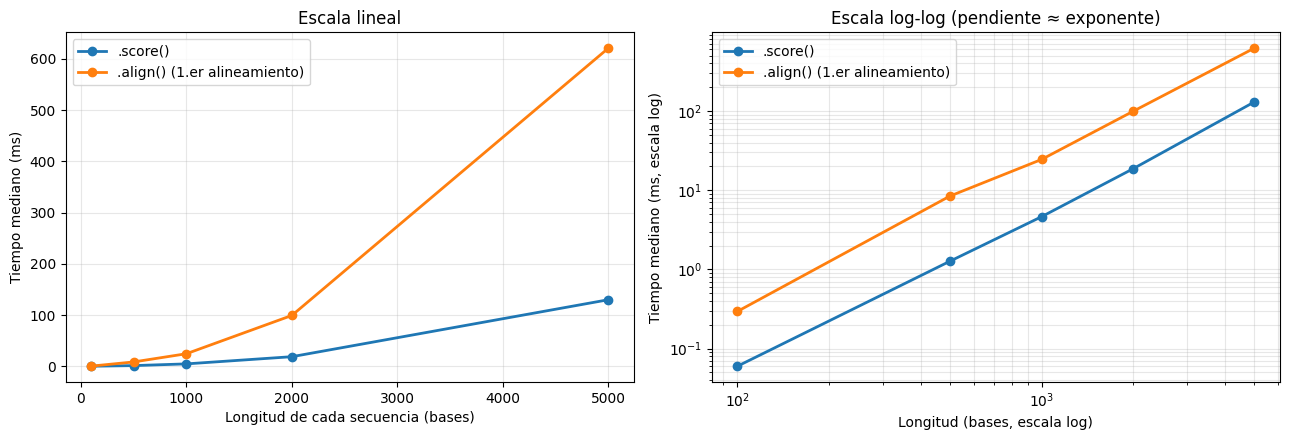

Exponente empírico de score_mediana_ms: 1.95  (cuadrático teórico = 2)
Exponente empírico de align_mediana_ms: 1.94  (cuadrático teórico = 2)
Longitud ×50 -> tiempo de .score() ×2170 (si fuera exactamente cuadrático: ×2500)


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for columna, etiqueta in (("score_mediana_ms", ".score()"), ("align_mediana_ms", ".align() (1.er alineamiento)")):
    axes[0].plot(df_tiempos["longitud"], df_tiempos[columna], marker="o", linewidth=2, label=etiqueta)
    axes[1].loglog(df_tiempos["longitud"], df_tiempos[columna], marker="o", linewidth=2, label=etiqueta)

axes[0].set_xlabel("Longitud de cada secuencia (bases)")
axes[0].set_ylabel("Tiempo mediano (ms)")
axes[0].set_title("Escala lineal")
axes[1].set_xlabel("Longitud (bases, escala log)")
axes[1].set_ylabel("Tiempo mediano (ms, escala log)")
axes[1].set_title("Escala log-log (pendiente ≈ exponente)")
for ax in axes:
    ax.grid(alpha=0.3, which="both")
    ax.legend()
plt.tight_layout()
plt.show()

# Exponente empírico: pendiente del ajuste lineal en log-log.
logs_l = np.log(df_tiempos["longitud"].to_numpy(dtype=float))
pendientes = {}
for columna in ("score_mediana_ms", "align_mediana_ms"):
    pendientes[columna] = np.polyfit(logs_l, np.log(df_tiempos[columna].to_numpy()), 1)[0]
    print(f"Exponente empírico de {columna}: {pendientes[columna]:.2f}  (cuadrático teórico = 2)")

factor_long = df_tiempos["longitud"].iloc[-1] / df_tiempos["longitud"].iloc[0]
factor_tiempo = df_tiempos["score_mediana_ms"].iloc[-1] / df_tiempos["score_mediana_ms"].iloc[0]
print(f"Longitud ×{factor_long:.0f} -> tiempo de .score() ×{factor_tiempo:.0f} "
      f"(si fuera exactamente cuadrático: ×{factor_long**2:.0f})")

### Extrapolación a volúmenes grandes

El enunciado pregunta si el *pipeline* escalará de 100 a 1 millón de datos. Con el exponente empírico se estiman dos escenarios, **solo como orden de magnitud** (la extrapolación supone que el comportamiento se mantiene y no considera la memoria ni la caché).

In [12]:
exp = pendientes["align_mediana_ms"]
t_ref = df_tiempos["align_mediana_ms"].iloc[-1]       # ms para 5000 bases
l_ref = df_tiempos["longitud"].iloc[-1]

# Escenario A: un único alineamiento de dos secuencias de 1 millón de bases.
t_a_ms = t_ref * (1_000_000 / l_ref) ** exp
print(f"A) Un alineamiento de 1.000.000 x 1.000.000 bases (.align()): ~{t_a_ms/1000/3600:,.1f} horas")
print(f"   Celdas de la matriz de programación dinámica: {1_000_000 * 1_000_000:.1e} (O(N·M) en memoria si se guarda el rastreo)")

# Escenario B: un millón de pares de secuencias cortas (100 bases).
t_b_ms = df_tiempos["align_mediana_ms"].iloc[0] * 1_000_000
print(f"B) 1.000.000 de pares de 100 bases, uno tras otro: ~{t_b_ms/1000/3600:,.1f} horas (un solo núcleo)")

A) Un alineamiento de 1.000.000 x 1.000.000 bases (.align()): ~5.0 horas
   Celdas de la matriz de programación dinámica: 1.0e+12 (O(N·M) en memoria si se guarda el rastreo)
B) 1.000.000 de pares de 100 bases, uno tras otro: ~0.1 horas (un solo núcleo)


**Interpretación.** Al duplicar la longitud, el tiempo se multiplica aproximadamente por cuatro: la matriz de programación dinámica para secuencias de longitudes $N$ y $M$ tiene $N\times M$ celdas, así que para secuencias igual de largas el coste es $O(N^2)$ y el exponente empírico del ajuste log-log queda próximo a 2. Las variaciones respecto a 2 se deben al ordenador, a la caché y a la sobrecarga fija de las secuencias cortas. `.align()` cuesta algo más que `.score()` porque además realiza el rastreo inverso y construye el alineamiento.

**Consecuencia para un ingeniero de datos.** Crecer en *número* de pares escala linealmente (escenario B: viable, paralelizable), pero crecer en *longitud* escala cuadráticamente (escenario A: inviable con programación dinámica exacta). Para volúmenes grandes se recurre a métodos heurísticos (BLAST, FASTA), a paralelismo o a alineamientos con banda.

**Aportaciones adicionales.** Semilla reproducible; mediana de varias repeticiones; medición separada de `.score()` y `.align()`; ajuste log-log del exponente; extrapolación explícita.

## Conclusiones generales

1. Los parámetros de apertura y extensión de huecos influyen en la puntuación y en el número de alineamientos óptimos. La transición entre múltiples empates y solución única es la recta $o = e$, verificada sobre toda la rejilla, y depende del esquema de puntuación, no solo de las secuencias.
2. La comparación de proteínas con BLOSUM62 resume la similitud de cada pareja en una matriz simétrica. El resultado depende de la matriz de sustitución y de las penalizaciones; para comparar matrices hay que normalizar las puntuaciones.
3. El coste de un alineamiento exacto crece de forma cuadrática con la longitud, lo que limita su uso a secuencias de tamaño moderado.

**Referencia docente:** *T03 · Bioinformática en laboratorio · Sesión 03: Alineamientos* y *Práctica 2*, material proporcionado para la asignatura.